# Task 4.1 — Time Series Decomposition

**Project:** Downtown San Diego Homeless Population Analysis  
**Organization:** Data Science Alliance  
**Source:** `data/MasterCounts_Adjusted_v2.csv` (canonical methodology-adjusted counts)  
**Methods:** additive classical decomposition and robust STL, both with a 12-month seasonal period

This notebook decomposes the overall reported neighborhood total and each of the seven requested neighborhood series into observed, trend, seasonal, and residual components. It annotates the April 2017 and May 2018 methodology changes and the March 2020 COVID-19 onset.

### Important scope decisions

- Only rows with `component == "total"` and `area_type == "neighborhood"` are used, preventing double-counting of component and sub-area rows.
- Four unreleased months in 2025 are retained as explicit gaps and linearly interpolated **only for decomposition**, never written back to the source data.
- `Outside Perimeter` begins in January 2021. The overall reported-footprint series therefore changes geographic coverage at that point; a fixed-footprint six-neighborhood sensitivity series is also computed.
- Decomposition describes recurring patterns; it does not establish that methodology or COVID markers caused them.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown
from statsmodels.tsa.seasonal import seasonal_decompose, STL

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 20)
plt.style.use("seaborn-v0_8-whitegrid")

DATA_PATH = Path("data/MasterCounts_Adjusted_v2.csv")
NEIGHBORHOODS = [
    "East Village", "City Center", "Columbia", "Marina",
    "Cortez", "Gaslamp", "Outside Perimeter"
]
EVENTS = {
    pd.Timestamp("2017-04-01"): ("Apr 2017 method", "#c0392b"),
    pd.Timestamp("2018-05-01"): ("May 2018 method", "#e67e22"),
    pd.Timestamp("2020-03-01"): ("COVID-19 onset", "#8e44ad"),
}
SEASONAL_PERIOD = 12

## 1. Load and validate the canonical series

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
required = {"date", "area", "component", "area_type", "total_count", "method"}
missing_columns = required.difference(df.columns)
assert not missing_columns, f"Missing required columns: {sorted(missing_columns)}"

monthly = (
    df.loc[
        (df["component"] == "total")
        & (df["area_type"] == "neighborhood")
        & (df["area"].isin(NEIGHBORHOODS)),
        ["date", "area", "total_count", "method"],
    ]
    .sort_values(["area", "date"])
    .copy()
)

assert monthly.duplicated(["date", "area"]).sum() == 0, "Duplicate area-month rows found"
assert set(monthly["area"].unique()) == set(NEIGHBORHOODS), "Unexpected neighborhood coverage"

coverage = monthly.groupby("area").agg(
    first_month=("date", "min"),
    last_month=("date", "max"),
    rows=("date", "size"),
    observed_months=("total_count", "count"),
)
coverage["missing_values"] = coverage["rows"] - coverage["observed_months"]
display(coverage)
print(f"Validated {len(monthly):,} neighborhood-total rows; duplicate area-month keys: 0")

,first_month,last_month,rows,observed_months,missing_values
area,,,,,
City Center,2017-01-01,2025-12-01,108,104,4
Columbia,2017-01-01,2025-12-01,108,104,4
Cortez,2017-01-01,2025-12-01,108,104,4
East Village,2017-01-01,2025-12-01,108,104,4
Gaslamp,2017-01-01,2025-12-01,108,104,4
Marina,2017-01-01,2025-12-01,108,104,4
Outside Perimeter,2021-01-01,2025-12-01,60,56,4


Validated 708 neighborhood-total rows; duplicate area-month keys: 0


## 2. Create continuous monthly analysis series

Linear interpolation is a transparent, minimal bridge across the four isolated unreleased 2025 months (July, August, October, and November). The notebook records every filled month below. Structural absence before `Outside Perimeter` reporting began is **not** imputed.

In [3]:
pivot = monthly.pivot(index="date", columns="area", values="total_count").sort_index()

def prepare_monthly(series):
    observed = series.dropna()
    idx = pd.date_range(observed.index.min(), observed.index.max(), freq="MS")
    regular = series.reindex(idx).astype(float)
    gaps = regular[regular.isna()].index
    filled = regular.interpolate(method="time", limit_direction="both")
    assert filled.notna().all()
    assert len(filled) >= 2 * SEASONAL_PERIOD
    filled.index.name = "date"
    return filled, gaps

# Reported footprint: sum all neighborhoods available in each month.
overall_raw = pivot.sum(axis=1, min_count=1).rename("Overall — reported footprint")
# Sensitivity series: six consistently represented core neighborhoods.
core_names = [n for n in NEIGHBORHOODS if n != "Outside Perimeter"]
core_raw = pivot[core_names].sum(axis=1, min_count=len(core_names)).rename("Overall — fixed core six")

raw_series = {overall_raw.name: overall_raw, core_raw.name: core_raw}
raw_series.update({name: pivot[name].rename(name) for name in NEIGHBORHOODS})

series_map, gap_rows = {}, []
for name, series in raw_series.items():
    prepared, gaps = prepare_monthly(series)
    series_map[name] = prepared
    gap_rows.extend({"series": name, "interpolated_month": d} for d in gaps)

gap_report = pd.DataFrame(gap_rows)
display(gap_report)
print("Source CSV remains unchanged; interpolation exists only in these in-memory analysis series.")

,series,interpolated_month
0,Overall — reported footprint,2025-07-01
1,Overall — reported footprint,2025-08-01
2,Overall — reported footprint,2025-10-01
3,Overall — reported footprint,2025-11-01
4,Overall — fixed core six,2025-07-01
5,Overall — fixed core six,2025-08-01
6,Overall — fixed core six,2025-10-01
7,Overall — fixed core six,2025-11-01
8,East Village,2025-07-01
9,East Village,2025-08-01


Source CSV remains unchanged; interpolation exists only in these in-memory analysis series.


## 3. Decomposition functions and event annotations

In [4]:
def decompose_pair(series):
    classical = seasonal_decompose(
        series, model="additive", period=SEASONAL_PERIOD, extrapolate_trend="freq"
    )
    stl = STL(series, period=SEASONAL_PERIOD, robust=True).fit()
    return classical, stl

def add_event_annotations(ax, index):
    first, last = index.min(), index.max()
    for when, (label, color) in EVENTS.items():
        if first <= when <= last:
            ax.axvline(when, color=color, linestyle="--", linewidth=1.1, alpha=0.9, label=label)

def plot_decomposition(name, series, classical, stl):
    components = [
        ("Observed", series, series),
        ("Trend", classical.trend, stl.trend),
        ("Seasonal", classical.seasonal, stl.seasonal),
        ("Residual", classical.resid, stl.resid),
    ]
    fig, axes = plt.subplots(4, 2, figsize=(16, 11), sharex=True)
    for row, (component, classic_values, stl_values) in enumerate(components):
        for col, (method, values) in enumerate(
            [("Classical additive", classic_values), ("Robust STL", stl_values)]
        ):
            ax = axes[row, col]
            ax.plot(values.index, values.values, color="#1f4e79", linewidth=1.4)
            add_event_annotations(ax, series.index)
            ax.set_ylabel(component)
            if row == 0:
                ax.set_title(method, fontweight="bold")
            if row == 3:
                ax.set_xlabel("Month")
            ax.xaxis.set_major_locator(mdates.YearLocator(2))
            ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    handles, labels = axes[0, 0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.955))
    subtitle = ""
    if name == "Outside Perimeter":
        subtitle = " — coverage starts Jan 2021; all requested reference events precede this series"
    fig.suptitle(f"{name}: monthly decomposition{subtitle}", fontsize=15, fontweight="bold", y=0.995)
    fig.text(
        0.01, 0.005,
        "Source: DSDP Clean & Safe monthly counts via MasterCounts_Adjusted_v2.csv. "
        "Dashed lines: methodology changes (Apr 2017, May 2018) and COVID onset (Mar 2020).",
        fontsize=8, color="#555555"
    )
    fig.tight_layout(rect=[0, 0.025, 1, 0.94])
    plt.show()

## 4. Overall series decomposition

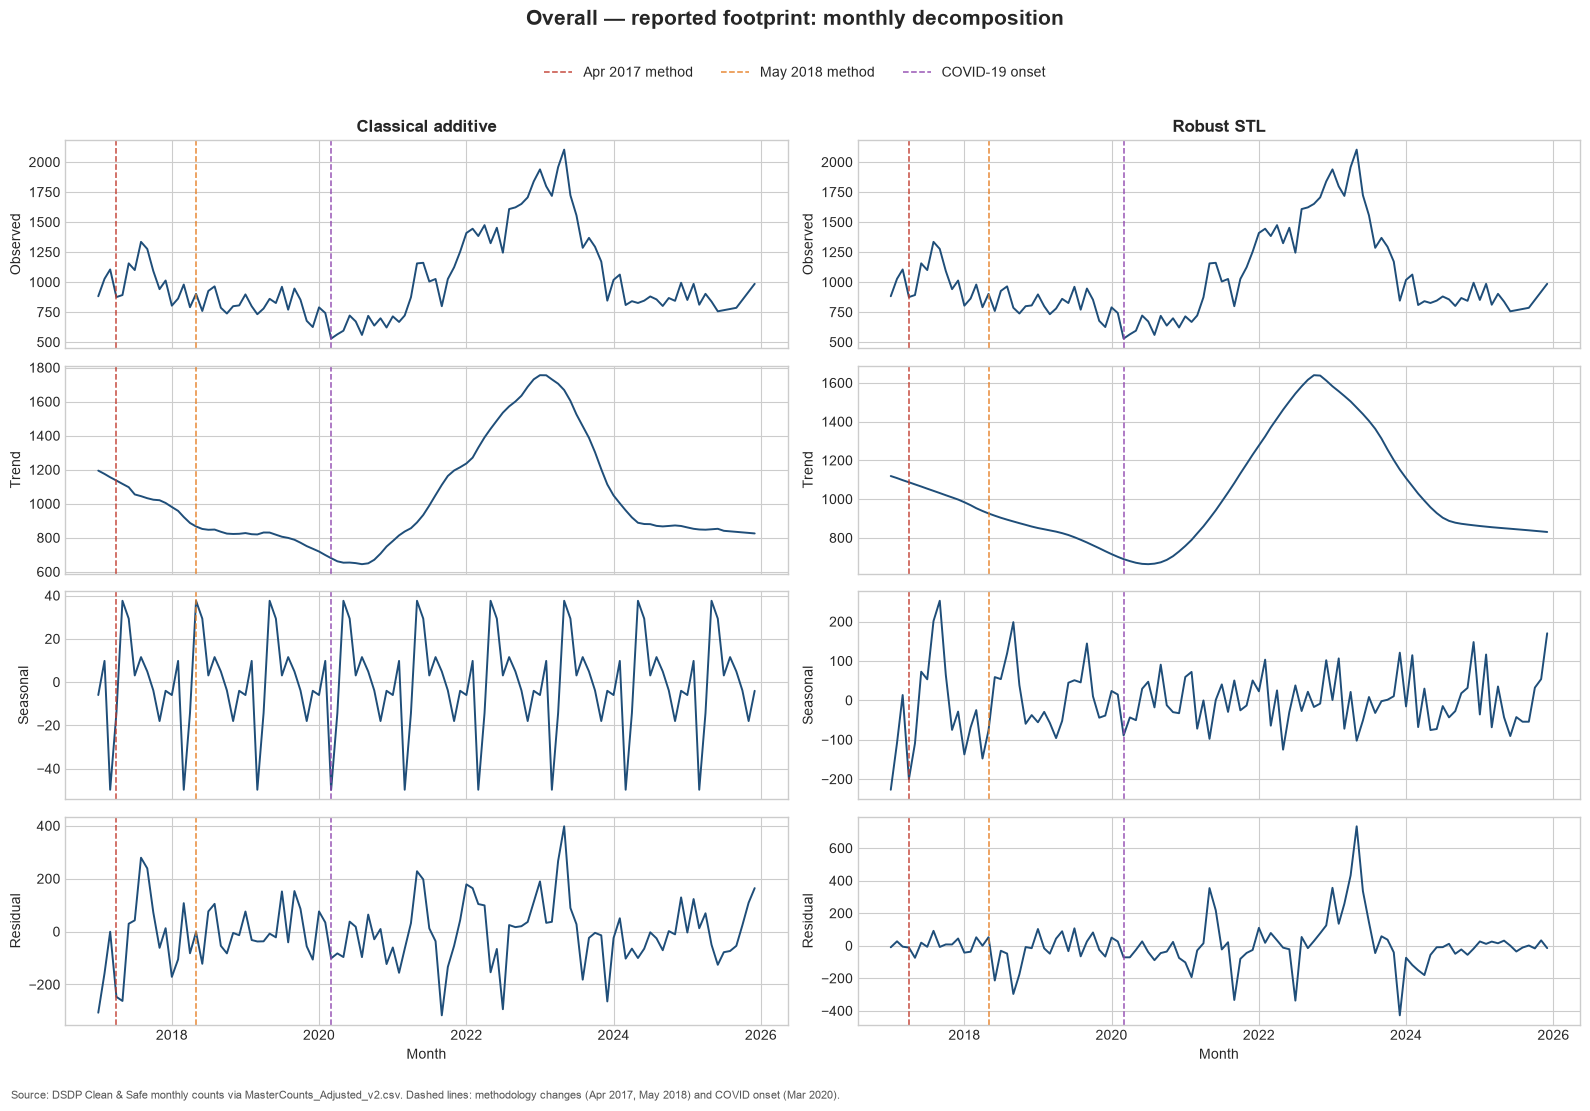

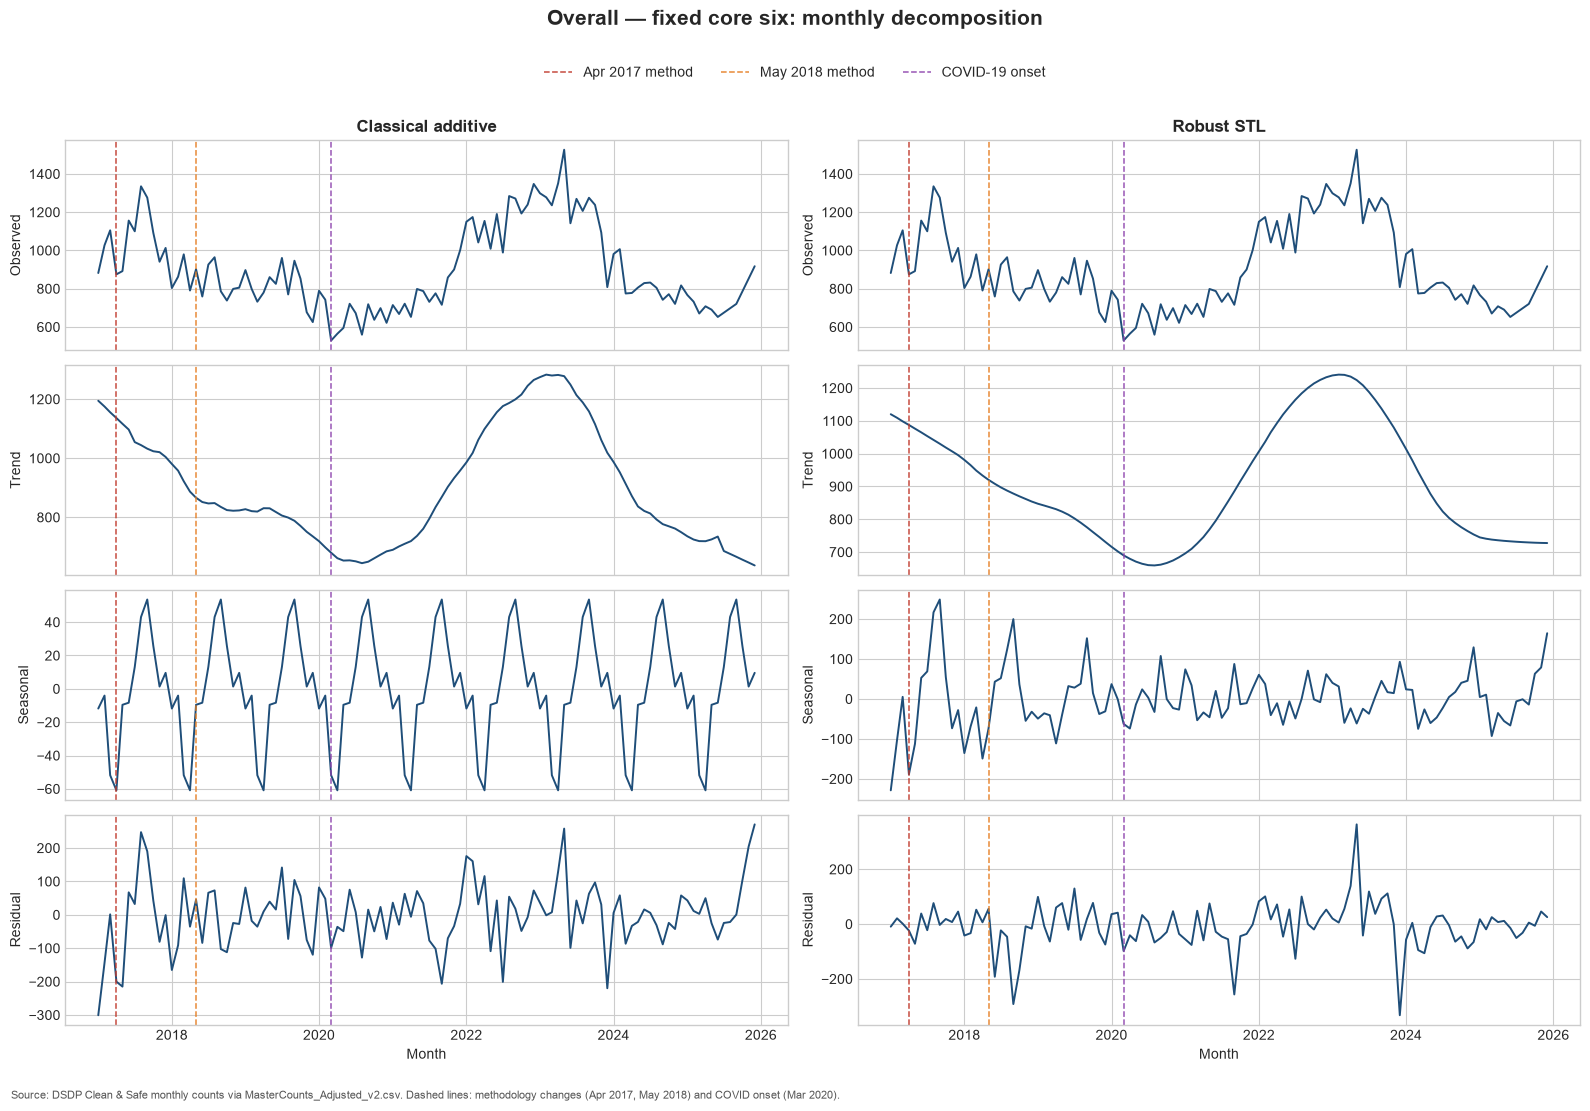

In [5]:
decompositions = {}
for name in ["Overall — reported footprint", "Overall — fixed core six"]:
    classical, stl = decompose_pair(series_map[name])
    decompositions[name] = {"classical": classical, "stl": stl}
    plot_decomposition(name, series_map[name], classical, stl)

The reported-footprint result answers the task's overall-series requirement. The fixed-core-six result is the comparability check: it excludes `Outside Perimeter`, whose reporting starts only in 2021, so the trend is not mechanically increased by that coverage expansion.

## 5. Neighborhood-level decompositions

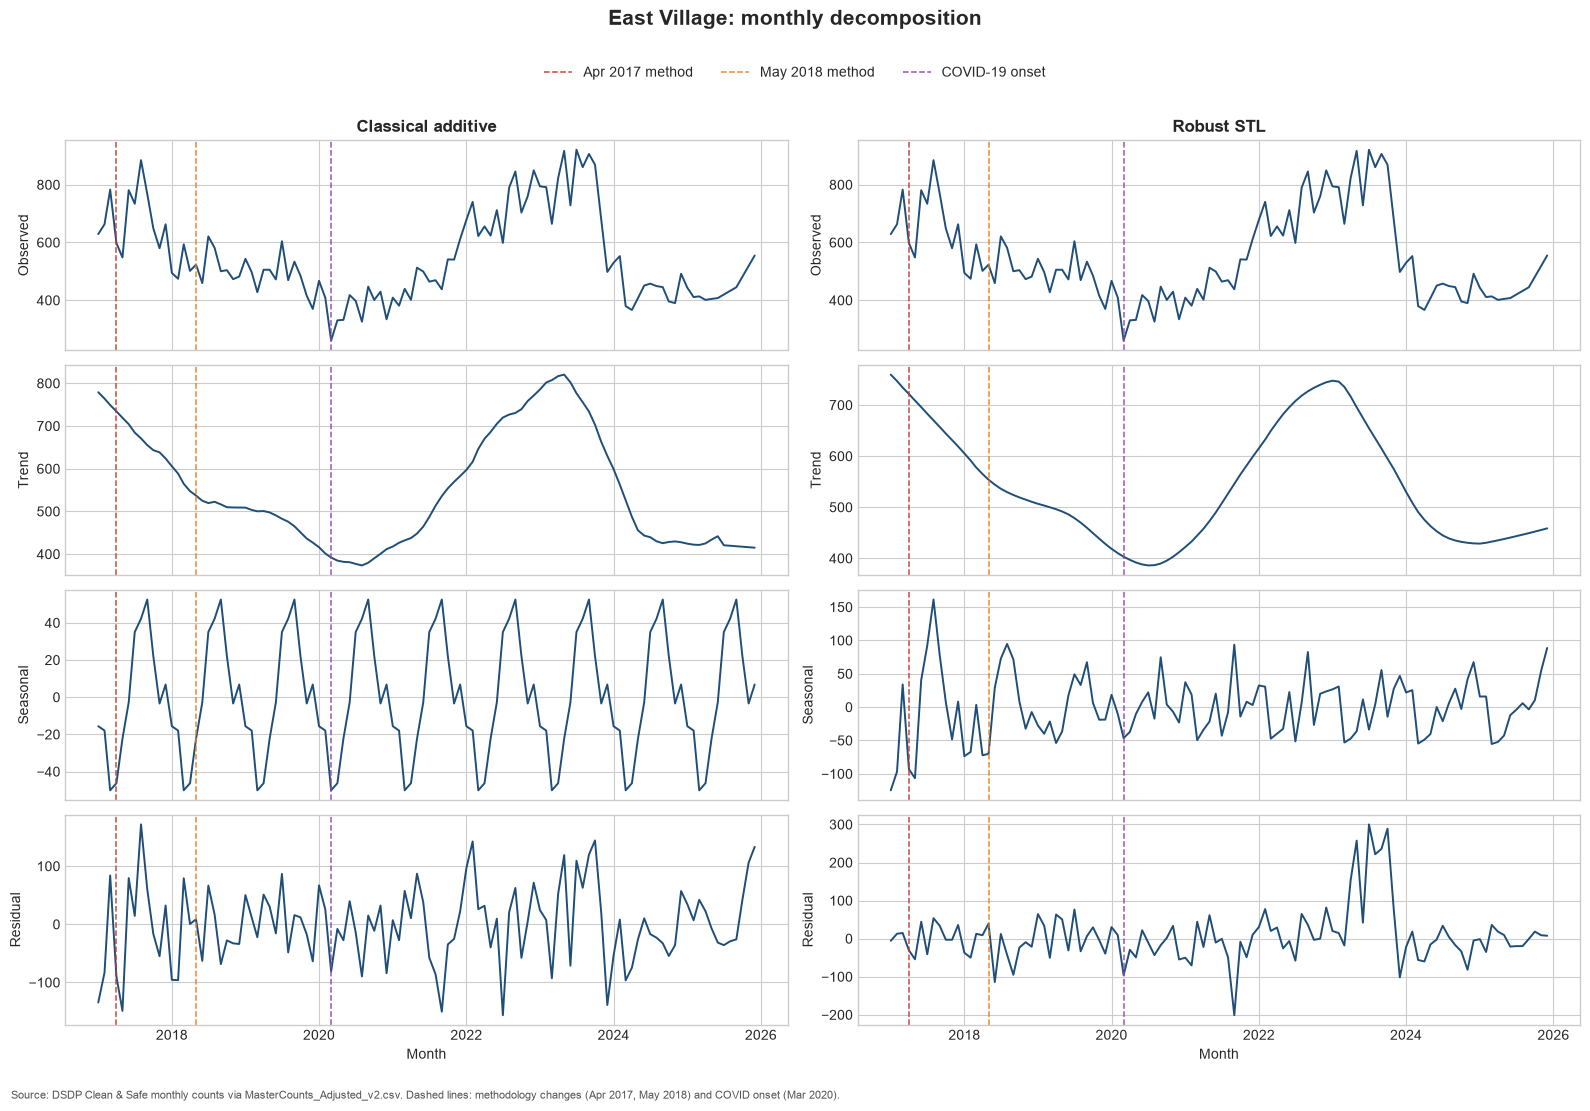

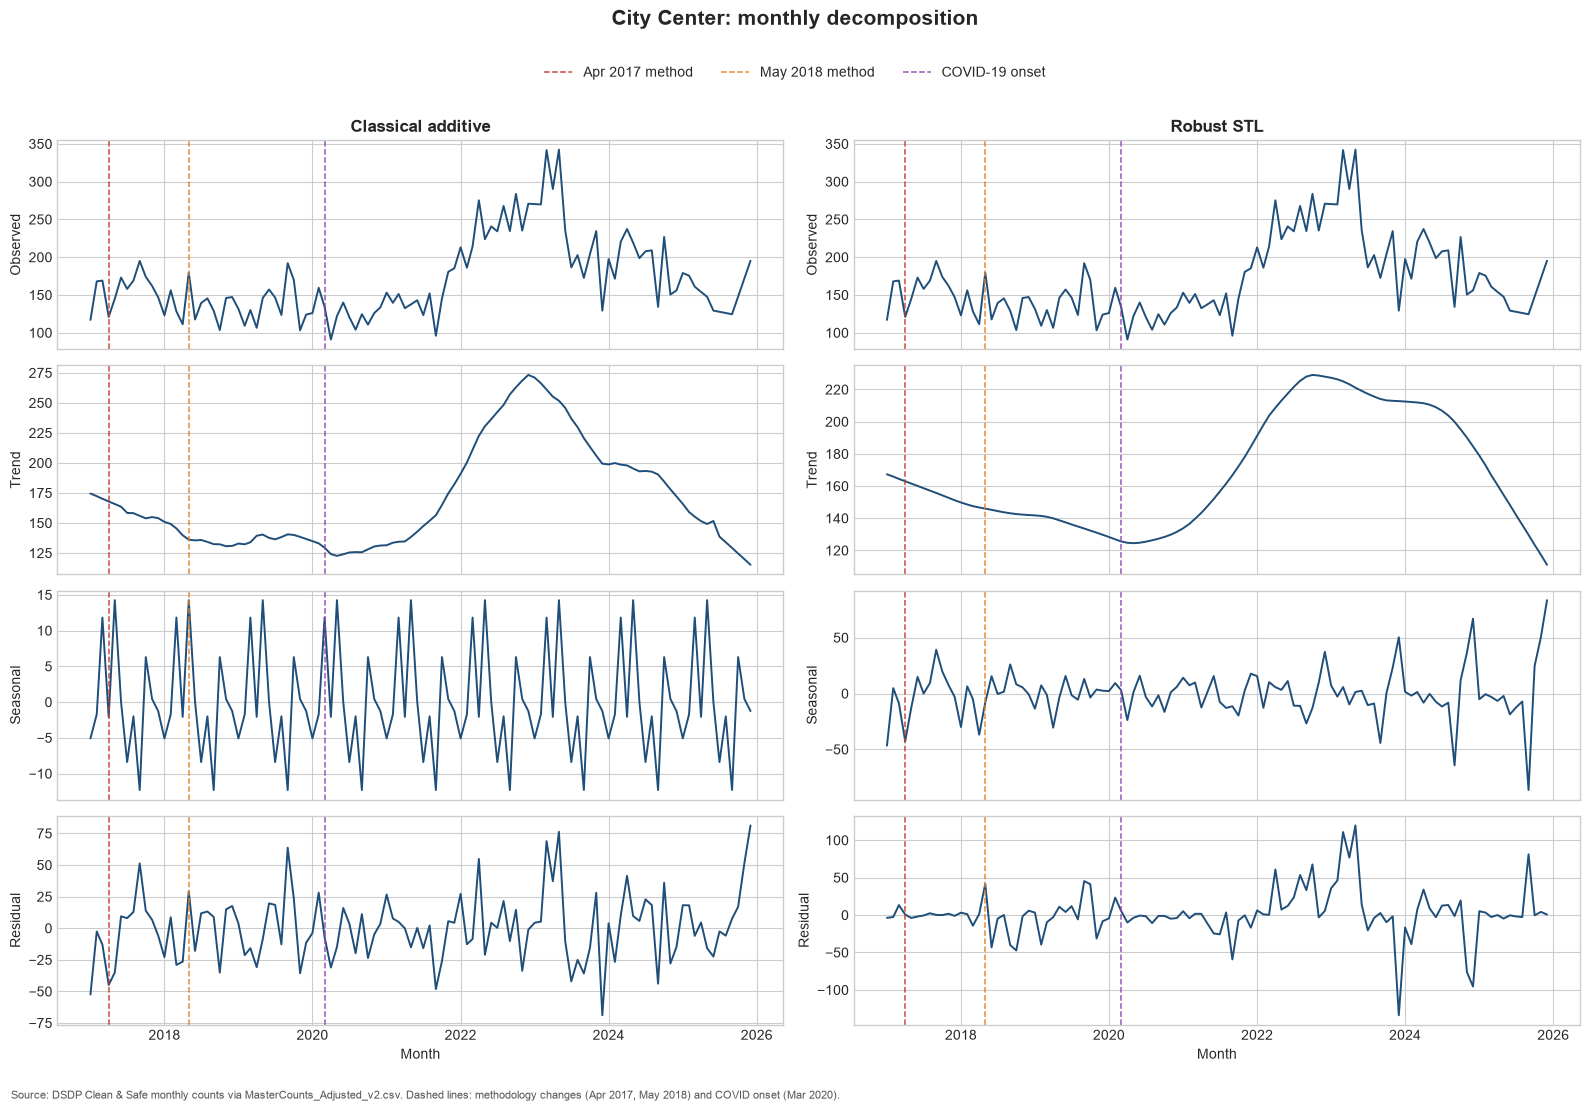

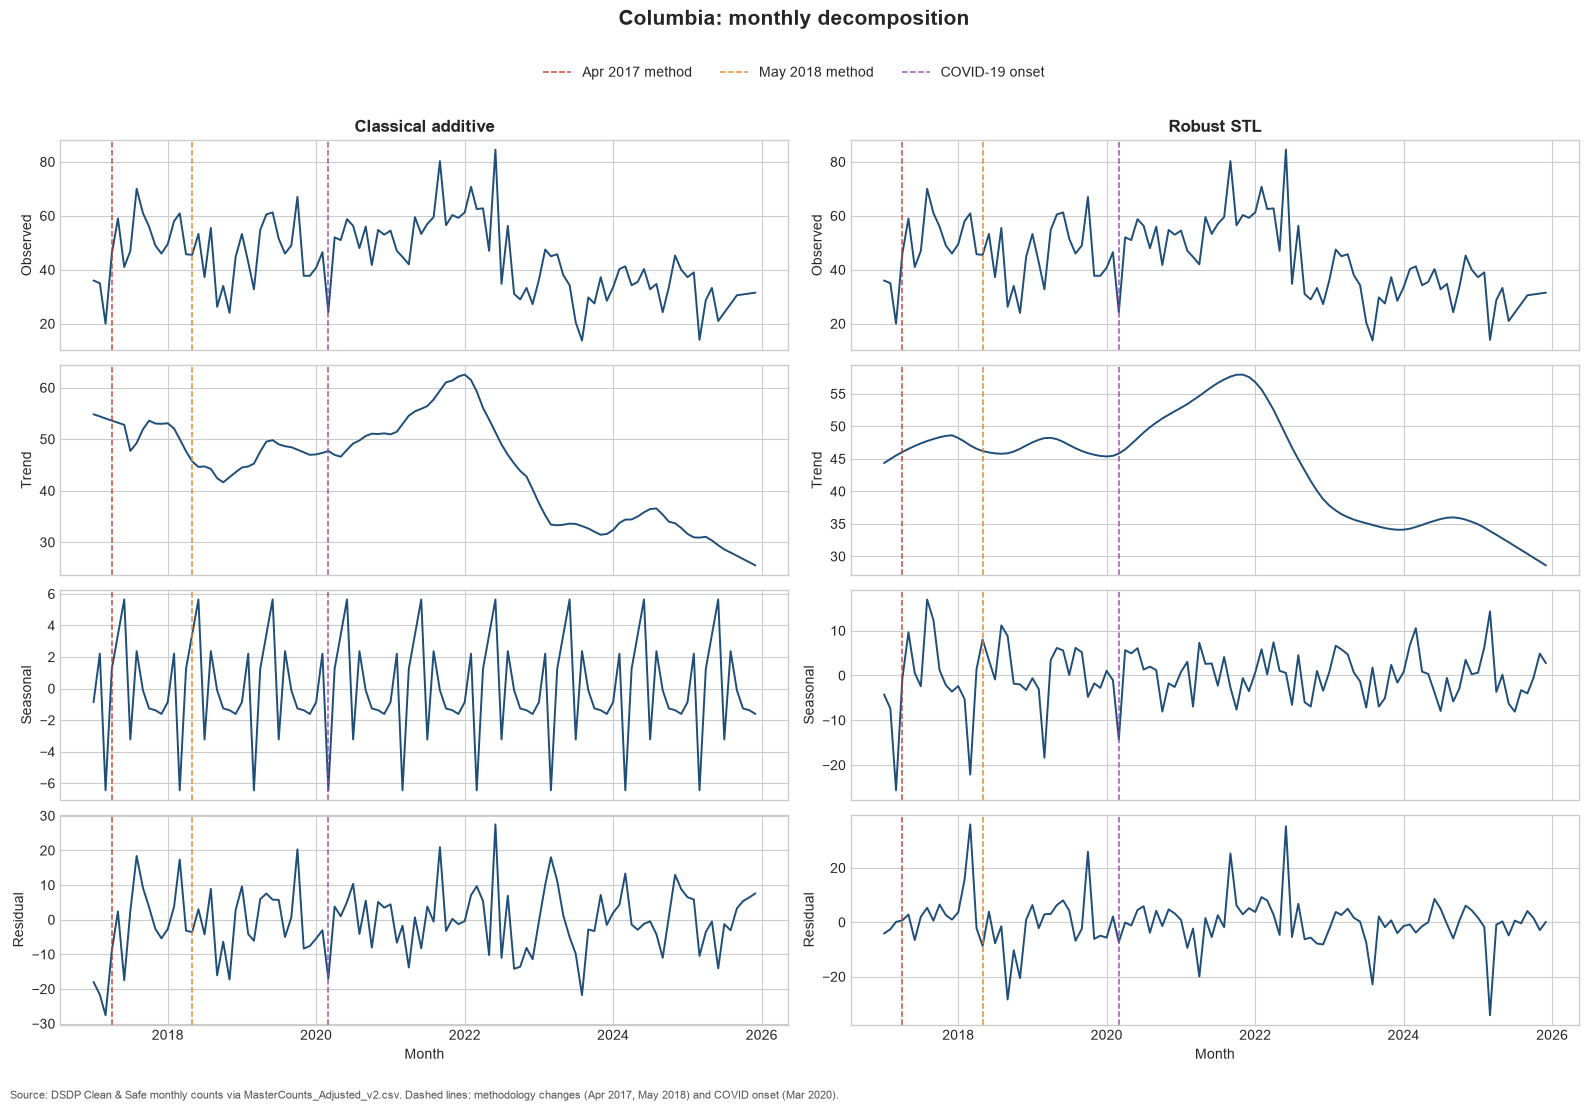

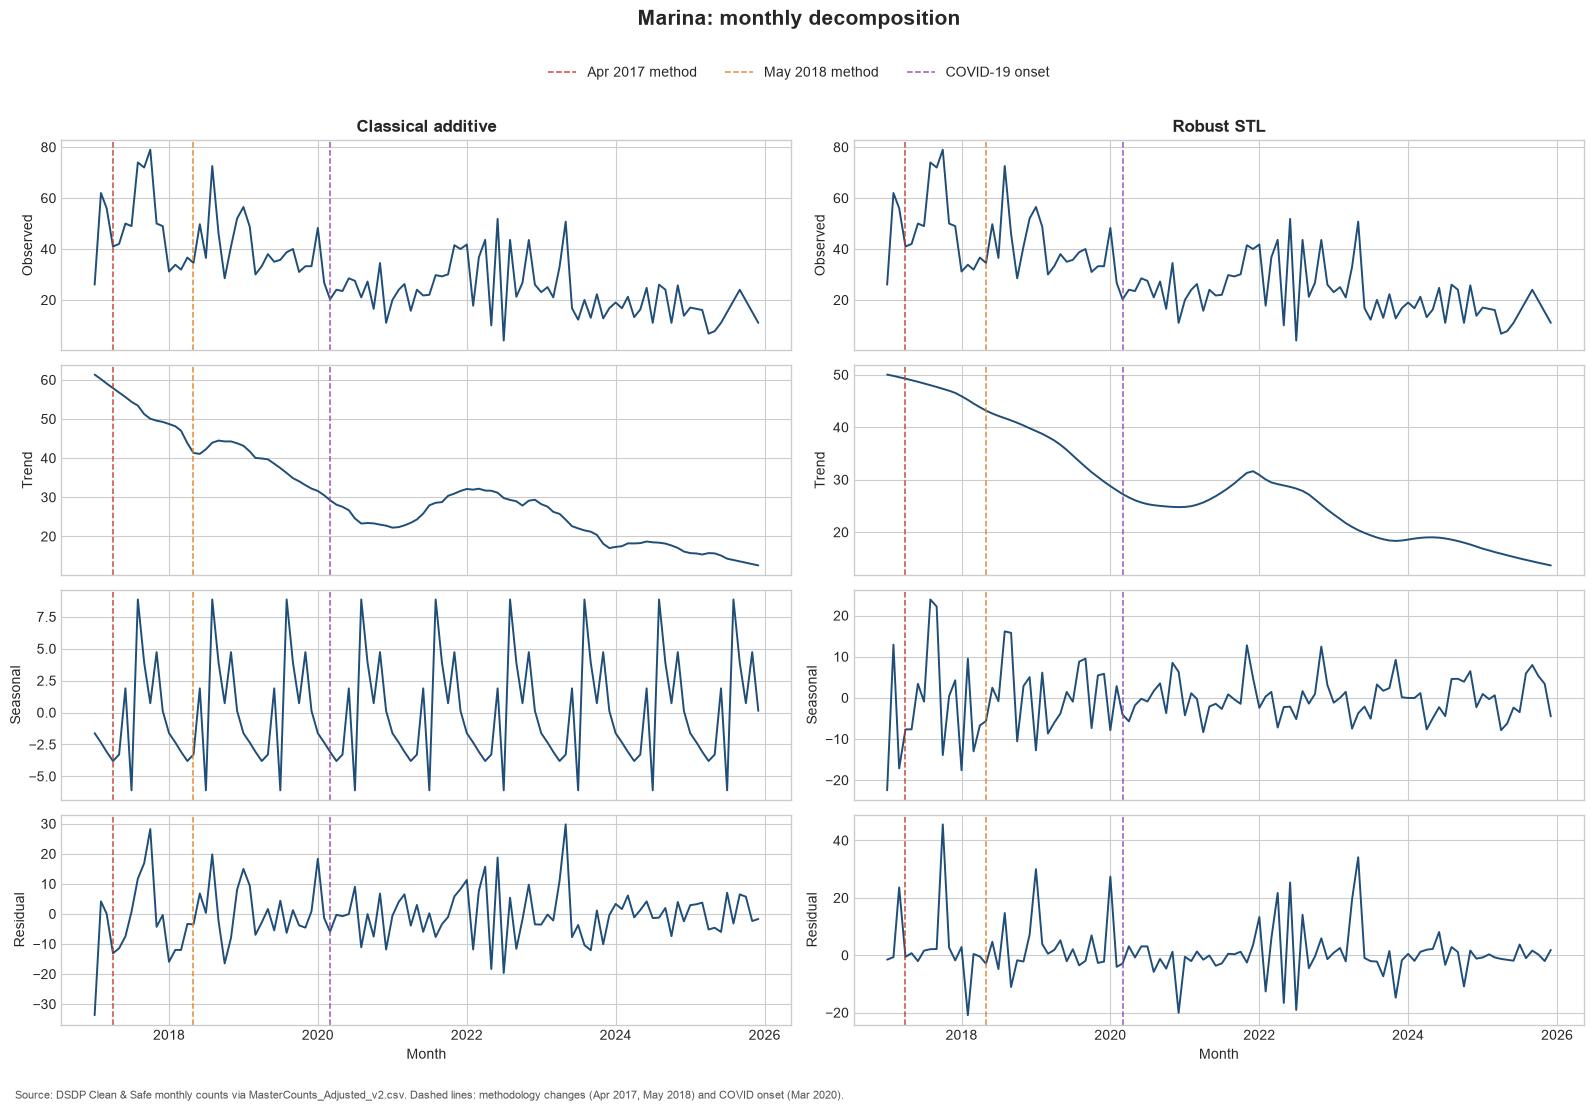

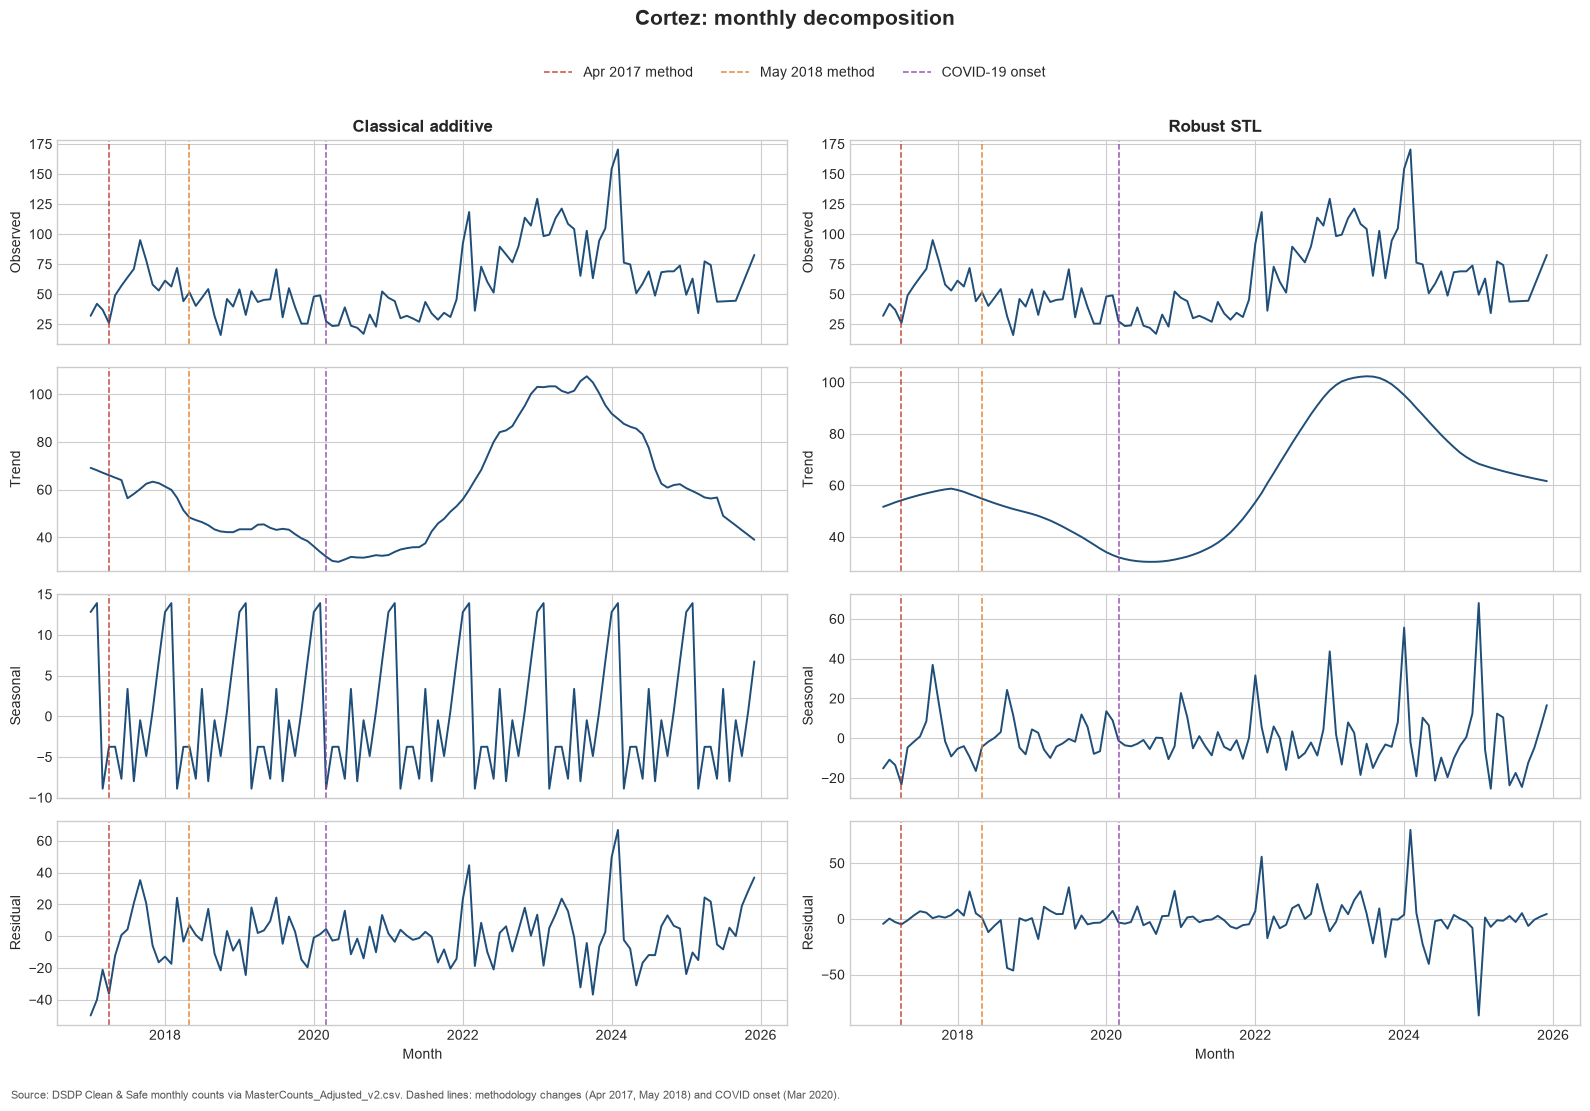

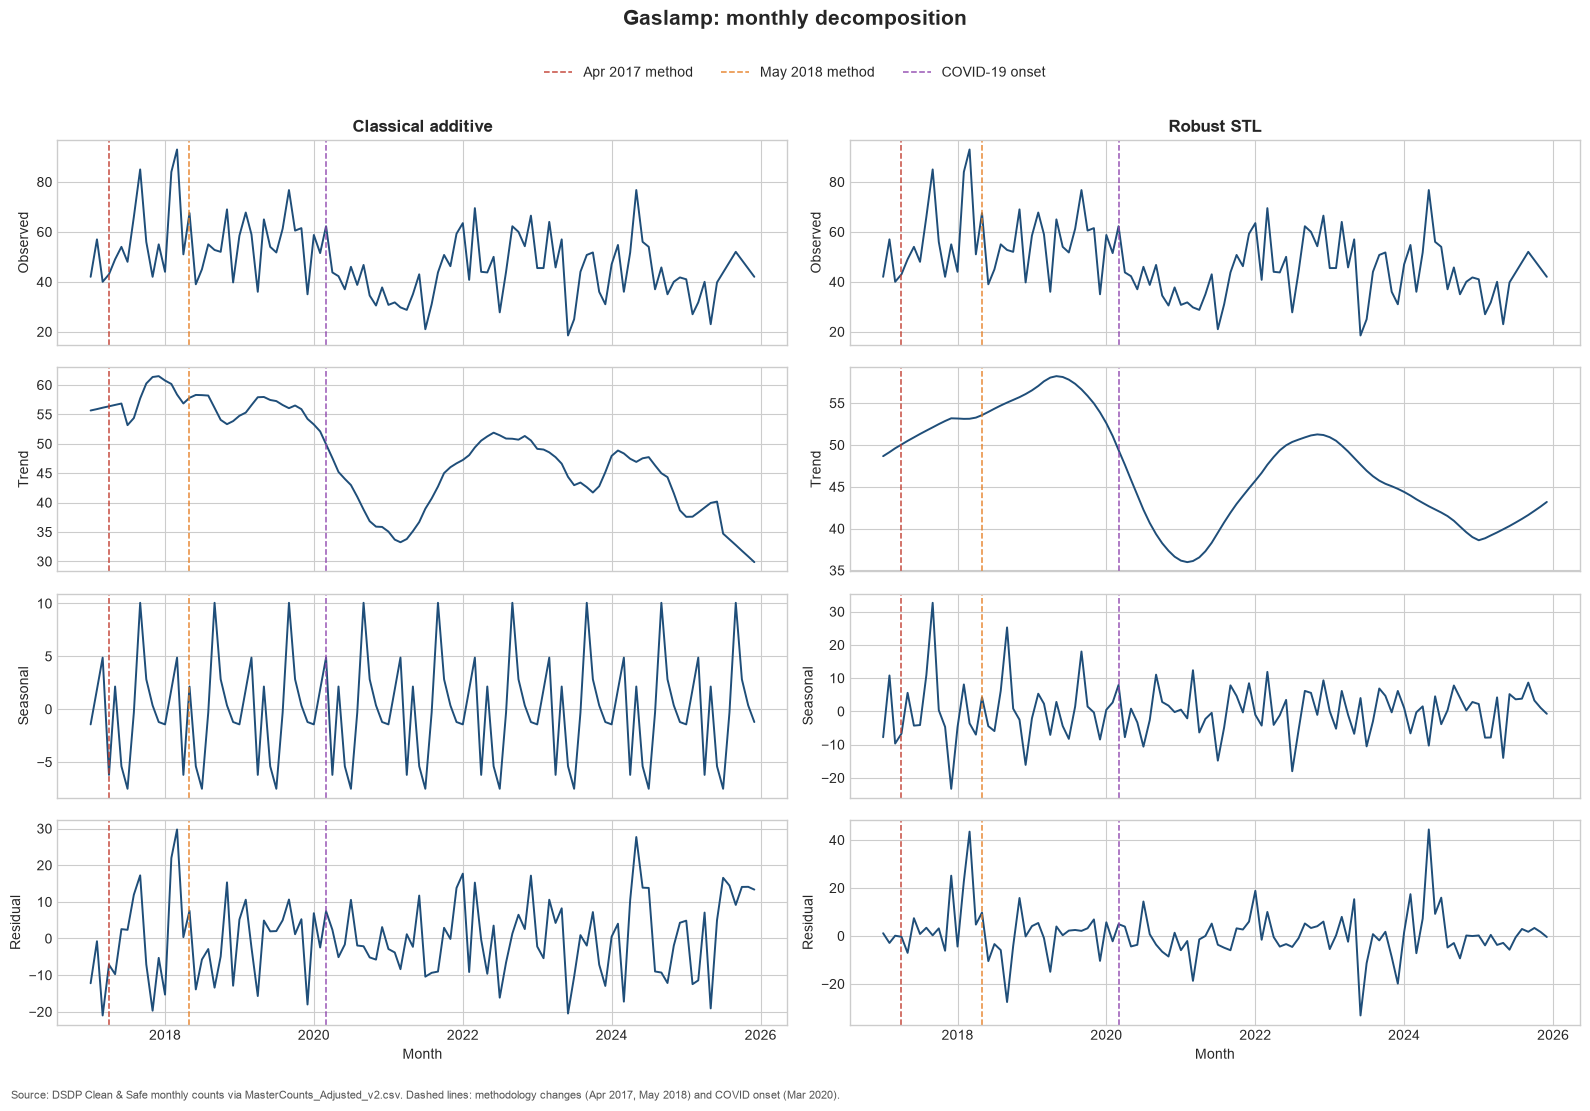

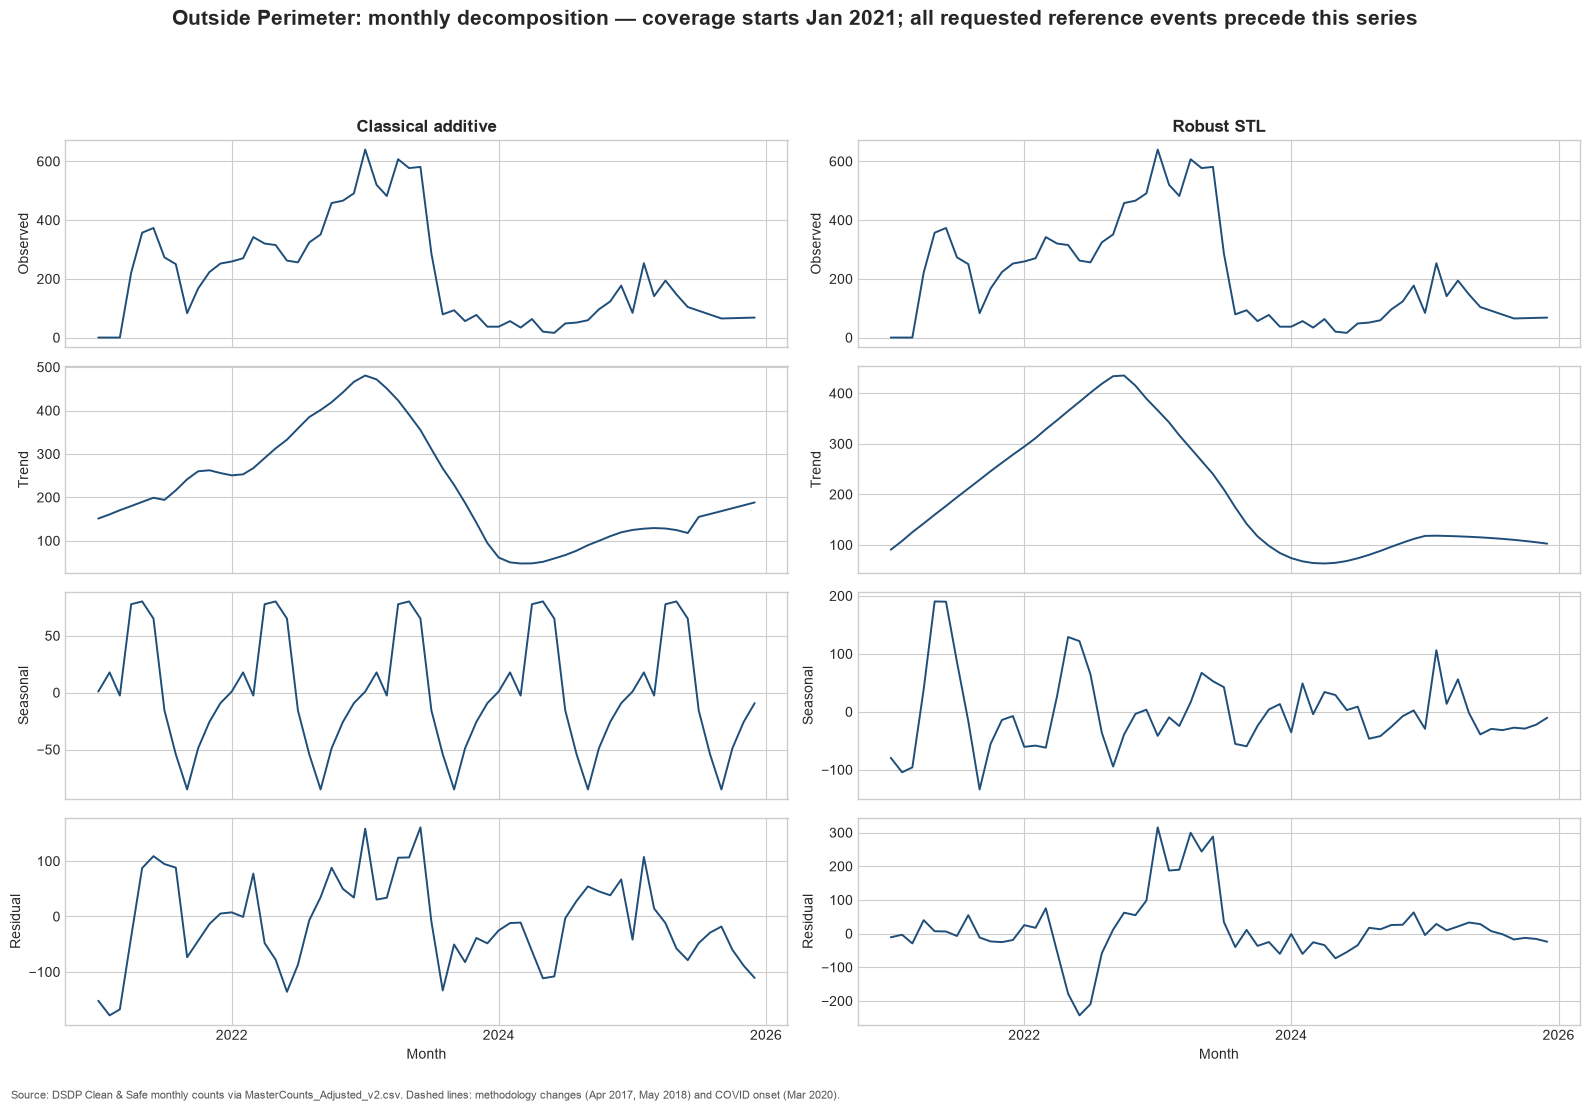

In [6]:
for name in NEIGHBORHOODS:
    classical, stl = decompose_pair(series_map[name])
    decompositions[name] = {"classical": classical, "stl": stl}
    plot_decomposition(name, series_map[name], classical, stl)

## 6. Diagnostics and interpretable seasonal summaries

In [7]:
month_names = pd.Series(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    index=range(1, 13),
)
rows = []
for name, results in decompositions.items():
    series = series_map[name]
    stl = results["stl"]
    seasonal_by_month = pd.Series(stl.seasonal, index=series.index).groupby(series.index.month).mean()
    resid = pd.Series(stl.resid, index=series.index)
    strength = max(0.0, 1.0 - np.var(resid) / np.var(resid + stl.seasonal))
    rows.append({
        "series": name,
        "start": series.index.min().date(),
        "end": series.index.max().date(),
        "months": len(series),
        "peak_season_month": month_names.loc[seasonal_by_month.idxmax()],
        "peak_season_effect": seasonal_by_month.max(),
        "trough_season_month": month_names.loc[seasonal_by_month.idxmin()],
        "trough_season_effect": seasonal_by_month.min(),
        "STL_seasonal_strength": strength,
        "STL_residual_SD": resid.std(),
    })

diagnostics = pd.DataFrame(rows).set_index("series")
display(diagnostics.round(3))

,start,end,months,peak_season_month,peak_season_effect,trough_season_month,trough_season_effect,STL_seasonal_strength,STL_residual_SD
series,,,,,,,,,
Overall — reported footprint,2017-01-01,2025-12-01,108,Sep,74.868,May,-81.396,0.071,141.198
Overall — fixed core six,2017-01-01,2025-12-01,108,Sep,101.660,Apr,-72.544,0.319,84.806
East Village,2017-01-01,2025-12-01,108,Sep,60.755,Apr,-53.179,0.263,73.303
City Center,2017-01-01,2025-12-01,108,Dec,28.978,Apr,-18.354,0.006,32.577
Columbia,2017-01-01,2025-12-01,108,Aug,4.767,Mar,-6.279,0.127,9.393
Marina,2017-01-01,2025-12-01,108,Aug,7.413,Jan,-7.517,0.099,9.760
Cortez,2017-01-01,2025-12-01,108,Jan,24.315,Mar,-11.119,0.160,17.366
Gaslamp,2017-01-01,2025-12-01,108,Sep,13.811,Jul,-8.054,0.206,10.371
Outside Perimeter,2021-01-01,2025-12-01,60,May,82.649,Sep,-71.477,0.192,100.442


In [8]:
overall_diag = diagnostics.loc["Overall — reported footprint"]
core_diag = diagnostics.loc["Overall — fixed core six"]
summary_lines = [
    "### Reproducible takeaways",
    "",
    f"- The reported-footprint STL seasonal component peaks in **{overall_diag['peak_season_month']}** "
    f"({overall_diag['peak_season_effect']:.1f} people relative to trend) and is lowest in "
    f"**{overall_diag['trough_season_month']}** ({overall_diag['trough_season_effect']:.1f}).",
    f"- Its estimated seasonal strength is **{overall_diag['STL_seasonal_strength']:.3f}**; values near zero imply "
    "that irregular variation dominates the recurring monthly pattern.",
    f"- The fixed-core-six seasonal strength is **{core_diag['STL_seasonal_strength']:.3f}**, providing a "
    "coverage-consistent benchmark for interpreting the overall series.",
    "- Classical and STL estimates are shown together because robust STL reduces the influence of extreme months, "
    "while the classical decomposition supplies a familiar moving-average benchmark.",
]
display(Markdown("\n".join(summary_lines)))

### Reproducible takeaways

- The reported-footprint STL seasonal component peaks in **Sep** (74.9 people relative to trend) and is lowest in **May** (-81.4).
- Its estimated seasonal strength is **0.071**; values near zero imply that irregular variation dominates the recurring monthly pattern.
- The fixed-core-six seasonal strength is **0.319**, providing a coverage-consistent benchmark for interpreting the overall series.
- Classical and STL estimates are shown together because robust STL reduces the influence of extreme months, while the classical decomposition supplies a familiar moving-average benchmark.

## 7. Limitations and handoff notes

- These are additive decompositions with a fixed 12-month period. They summarize within-year recurrence but do not prove seasonality is stable over the full study period.
- The April 2017 and May 2018 lines denote month-normalized multiplier-regime transitions documented in `docs/MethodologyChangeLog.md`; the underlying MAY2018 source packet is dated May 31, 2018. March 2020 is a contextual COVID marker. Formal structural-break and stationarity tests belong to later Assignment 4 tasks.
- `total_count` is the methodology-adjusted public-facing measure requested for this task. For causal break testing or forecasting, the methodology log recommends checking `raw_count` as a sensitivity outcome.
- The four interpolated 2025 values exist solely to satisfy the equally spaced, gap-free input expected by both decomposition routines. They should not be treated as observed counts.
- `Outside Perimeter` begins in 2021, so its decomposition uses a shorter window and cannot display the earlier reference events within its observed x-range.

**Deliverable:** `TimeSeries_Decomposition.ipynb`  
**Verification target:** notebook executes from top to bottom without errors and preserves the source CSV unchanged.